# A3 · Exploring the messy export (EDA)

**You are the detective.** `data/raw_emr_export.csv` is what the hospital handed over. **Eight kinds of data problem** are hidden in it. Find as many as you can.

**Rules**
1. **Look, don't change.** Nothing in this notebook modifies the data; fixing happens in A4. EDA that "fixes as it goes" destroys the evidence.
2. **Write every finding in the problem log** (next cell) with *numbers*: how many rows, what proportion, an example.
3. **Don't open** `slotpred/_messy_export.py` (spoiler) or `data/_hidden_truth.csv` (that's for the oracle only, never for a model).

Each check has a short **why**, given code where it's plumbing, and `TODO(you)` where the looking is yours.

## Problem log (fill this in as you go)

| # | Problem | Evidence (numbers, example) | Rows affected | Likely cause | Fix to try in A4 |
|---|---|---|---|---|---|
| 1 | Exact duplicate rows | 175 rows are exact copies; 175 repeated `appointment_id`s, all identical (e.g. A000014, A043622) | 175 (0.4%) | Export/ETL ran twice or re-sent records | Drop duplicates on `appointment_id` (keep first) |
| 2 | Inconsistent category labels | `doctor` has 105 distinct values vs 21 real (e.g. "Dr. Nikhil Verma", " dr nikhil verma", "DR NIKHIL VERMA", "Nikhil V."); `visit_type` has 12 vs 3 (`New`, `NEW`, `new visit`, `follow up`, `followup`, `report review`...) | ~1.4k visit_type rows plus many doctor variants | Free-text entry, no controlled vocabulary | Strip, lower-case, remove "Dr.", map initials/variants to the canonical 21 doctors / 3 visit types |
| 3 | Placeholder age 999 | `age.max()` = 999; 41 rows have age 999 (age 0 appears in 407 rows, check if real) | 41 (0.09%) | 999 used as an "unknown" code | Replace 999 with NaN, then impute (median by department / visit type) |
| 4 | Missing age | 863 NaN (1.96%); rate flat across clinics (1.88-2.10%); also why `age` is float | 863 | MCAR-like random omission | Impute median (+ missing flag); dropping is safe |
| 5 | Missing consult_end (target is NaN) | 100 NaN (0.23%), spread across all clinics and months (0.15-0.32%/month) | 100 | MCAR-like: visit never closed in the EMR | Drop from training (no target) |
| 6 | Impossible durations | 214 consults under 1 min (min 0.03 min = 2 s) and 455 over 120 min (up to ~280 min), spread over all clinics/months | 669 (1.5%) | Data entry / clock errors | Apply domain rule (1 <= minutes <= 120), drop or cap; use log-scale IQR (778 flags vs 2,204 raw) |
| 7 | Whitefield process change (Mar-Apr 2026) | `consult_start == check_in` in 1,753 rows, all Whitefield, Mar (936) + Apr (817); Whitefield monthly median 26.7-28 min vs ~12 min other months | 1,753 | Software/process change copied `check_in` into `consult_start`, so target includes waiting time | Exclude or re-derive those rows, or add a period flag |
| 8 | Timestamp order broken | `consult_end <= consult_start` (0 min) in 4 rows: Indiranagar 2, Koramangala 1, Whitefield 1; `consult_start < check_in` in 0 rows | 4 | Clock / entry error | Drop (non-positive duration) |

In [75]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slotpred.eda import load_raw, log_hist, monthly_median

raw = load_raw()
print(raw.shape)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
(43922, 16)


## Check 1 - Shape and types

**Why:** a column with the wrong type hides problems. Dates stored as text can't be compared; a number stored as float may be hiding missing values (NaN forces int to float).

In [76]:
display(raw.head())
raw.dtypes

,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,interpreter,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end
0,A034847,2026-07-13,14:30,Koramangala,Sanjay Patil,Paediatrics,P03953,Arjun,6.0,False,review,2,False,2026-07-13 14:14:20,2026-07-13 14:33:59,2026-07-13 14:41:08
1,A015590,2026-03-30,11:15,Koramangala,Rahul Menon,Cardiology,P03927,Uma,30.0,False,follow-up,0,False,2026-03-30 11:08:32,2026-03-30 11:19:00,2026-03-30 11:32:00
2,A038795,2026-08-04,14:45,Koramangala,Sanjay Patil,Paediatrics,P04054,Nikhil,7.0,False,follow-up,1,False,2026-08-04 14:35:48,2026-08-04 14:48:36,2026-08-04 14:58:02
3,A024657,2026-05-18,17:45,Indiranagar,Imran Khan,General Medicine,P00278,Kabir,43.0,False,new,1,False,2026-05-18 17:25:30,2026-05-18 17:45:43,2026-05-18 17:58:27
4,A033369,2026-07-04,14:30,Whitefield,Neha Gupta,General Medicine,P00762,Priya,38.0,False,new,0,False,2026-07-04 14:13:35,2026-07-04 14:40:13,2026-07-04 14:52:08


appointment_id        str
date                  str
slot_time             str
clinic                str
doctor                str
department            str
patient_id            str
patient_name          str
age               float64
interpreter          bool
visit_type            str
prior_reports       int64
teleconsult          bool
check_in              str
consult_start         str
consult_end           str
dtype: object

**Questions:** Which columns are text but should be dates or times? Why might `age` be a float when ages are whole numbers?

*Answer:* consult_start and consult_end and check_in  should be tiem and and date should be date but now all are in string,beacuse age is missing values in few rows and automatic fill is there 

In [77]:
# Date column
raw["date"] = pd.to_datetime(raw["date"])

# Full timestamps (these are likely "HH:MM" strings or full datetimes)
for col in ["check_in", "consult_start", "consult_end"]:
    raw[col] = pd.to_datetime(raw[col], errors="coerce")

#raw["slot_time"] = pd.to_datetime(raw["slot_time"], errors="coerce").dt.time
#Better: combine with the date for a full datetime64 (best for modelling and EDA)
raw["slot_dt"] = pd.to_datetime(
    raw["date"].dt.strftime("%Y-%m-%d") + " " + raw["slot_time"].astype(str),
    errors="coerce",
)

In [78]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 43922 entries, 0 to 43921
Data columns (total 17 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   appointment_id  43922 non-null  str           
 1   date            43922 non-null  datetime64[us]
 2   slot_time       43922 non-null  str           
 3   clinic          43922 non-null  str           
 4   doctor          43922 non-null  str           
 5   department      43922 non-null  str           
 6   patient_id      43922 non-null  str           
 7   patient_name    43922 non-null  str           
 8   age             43059 non-null  float64       
 9   interpreter     43922 non-null  bool          
 10  visit_type      43922 non-null  str           
 11  prior_reports   43922 non-null  int64         
 12  teleconsult     43922 non-null  bool          
 13  check_in        43922 non-null  datetime64[us]
 14  consult_start   43922 non-null  datetime64[us]
 15  consult_end  

## Check 2 - Keys and duplicates

**Why:** `appointment_id` should identify exactly one visit. Duplicates count a visit twice: double weight in training, and if one copy lands in train and the other in test, the model is tested on a visit it has already seen (a form of leakage).

In [79]:
# TODO(you):
# 1. How many rows are EXACT duplicates of another row?           hint: raw.duplicated()

display(raw.duplicated().sum())

# 2. How many appointment_ids appear more than once?              hint: raw["appointment_id"].duplicated()
display(raw["appointment_id"].duplicated().sum())

# 3. Are the repeated ids always exact copies, or do some differ?  compare 1 and 2
display(raw[raw["appointment_id"].duplicated(keep=False)].sort_values("appointment_id"))
# they are exactly the same

np.int64(175)

np.int64(175)

,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,interpreter,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
8128,A000014,2026-01-01,16:30,HSR,Divya Rao,Dermatology,P01978,Bhavna,54.0,False,follow-up,0,False,2026-01-01 16:14:49,2026-01-01 16:30:06,2026-01-01 16:33:59,2026-01-01 16:30:00
41097,A000014,2026-01-01,16:30,HSR,Divya Rao,Dermatology,P01978,Bhavna,54.0,False,follow-up,0,False,2026-01-01 16:14:49,2026-01-01 16:30:06,2026-01-01 16:33:59,2026-01-01 16:30:00
8785,A000090,2026-01-01,12:45,Whitefield,Neha Gupta,General Medicine,P02195,Arun,54.0,False,review,2,True,2026-01-01 12:43:14,2026-01-01 12:46:37,2026-01-01 12:47:13,2026-01-01 12:45:00
24695,A000090,2026-01-01,12:45,Whitefield,Neha Gupta,General Medicine,P02195,Arun,54.0,False,review,2,True,2026-01-01 12:43:14,2026-01-01 12:46:37,2026-01-01 12:47:13,2026-01-01 12:45:00
13428,A000149,2026-01-01,15:30,HSR,Rohan Desai,ENT,P04703,Krishna,48.0,False,follow-up,1,False,2026-01-01 15:13:04,2026-01-01 15:37:11,2026-01-01 15:49:29,2026-01-01 15:30:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37182,A042685,2026-08-26,09:00,Indiranagar,Divya Rao,Dermatology,P05109,Bhavna,39.0,False,new,0,False,2026-08-26 08:52:59,2026-08-26 09:08:17,2026-08-26 09:17:25,2026-08-26 09:00:00
3441,A043465,2026-08-29,15:45,Indiranagar,Imran Khan,General Medicine,P00639,Pooja,24.0,False,follow up,0,True,2026-08-29 15:42:17,2026-08-29 15:46:38,2026-08-29 15:53:07,2026-08-29 15:45:00
6232,A043465,2026-08-29,15:45,Indiranagar,Imran Khan,General Medicine,P00639,Pooja,24.0,False,follow up,0,True,2026-08-29 15:42:17,2026-08-29 15:46:38,2026-08-29 15:53:07,2026-08-29 15:45:00
8275,A043622,2026-08-31,09:45,HSR,Kavita Iyer,Gynaecology,P05117,Arjun,51.0,False,review,6,True,2026-08-31 09:35:53,2026-08-31 09:46:27,2026-08-31 09:59:40,2026-08-31 09:45:00


## Check 3 - Missing values

**Why:** *how many* is missing matters, but *which rows* matters more:

| Type | Meaning | Example | Danger |
|---|---|---|---|
| **MCAR** (missing completely at random) | Missingness unrelated to anything | A random export glitch | Low: dropping rows is fine |
| **MAR** (missing at random, given other columns) | Depends on something you can see | One clinic never records age | Medium: fill using that column |
| **MNAR** (missing not at random) | Depends on the missing value itself | End time missing because the visit was so long the doctor forgot | High: dropping biases the data |

In [80]:
# TODO(you):
# 1. Missing count AND percentage per column.                      hint: raw.isna().sum(), raw.isna().mean()
display(raw.isna().sum())
display(raw.isna().mean())
# 2. For each column with missing values: is the missing rate the same in every clinic? every month?
# display(raw.assign(missing=raw["age"].isna()).groupby("clinic")["missing"].sum())
# display(raw.assign(missing=raw["age"].isna()).groupby("clinic")["missing"].mean())

# display(
#     raw.groupby(raw["date"].dt.to_period("M"))["consult_end"]
#        .apply(lambda s: s.isna().mean())
# )


def missing_rate(df, col, by):
    #return df[col].isna().groupby(by).mean()
    # if has to compute mean and sum at a time 
    return df[col].isna().groupby(by).agg(["mean", "sum"])

display(missing_rate(raw, "age", raw["clinic"]))
display(missing_rate(raw, "consult_end", raw["date"].dt.to_period("M")))


#    hint: raw.assign(missing=raw["COL"].isna()).groupby("clinic")["missing"].mean()

appointment_id      0
date                0
slot_time           0
clinic              0
doctor              0
department          0
patient_id          0
patient_name        0
age               863
interpreter         0
visit_type          0
prior_reports       0
teleconsult         0
check_in            0
consult_start       0
consult_end       100
slot_dt             0
dtype: int64

appointment_id    0.000000
date              0.000000
slot_time         0.000000
clinic            0.000000
doctor            0.000000
department        0.000000
patient_id        0.000000
patient_name      0.000000
age               0.019648
interpreter       0.000000
visit_type        0.000000
prior_reports     0.000000
teleconsult       0.000000
check_in          0.000000
consult_start     0.000000
consult_end       0.002277
slot_dt           0.000000
dtype: float64

,mean,sum
clinic,,
HSR,0.019123,219
Indiranagar,0.021015,183
Jayanagar,0.020385,178
Koramangala,0.018794,140
Whitefield,0.018863,143


,mean,sum
date,,
2026-01,0.002093,12
2026-02,0.002843,14
2026-03,0.001836,10
2026-04,0.003240,18
2026-05,0.003123,17
2026-06,0.001953,11
2026-07,0.001764,10
2026-08,0.001450,8


## Check 4 - Categories

**Why:** "Dr. Deepak Rao", "DR DEEPAK RAO" and "Deepak R." are one doctor to a human and three doctors to a model, each with a third of the data.

**Reference from the hospital:** 21 doctors, 8 departments, 5 clinics, 3 visit types (`new`, `follow-up`, `review`). Every doctor belongs to exactly one department.

In [81]:
# TODO(you):
# 1. Number of distinct values in doctor, department, clinic, visit_type. Compare with the reference.   hint: .nunique()
display(raw["doctor"].nunique())
display(raw["department"].nunique())
display(raw["clinic"].nunique())
display(raw["visit_type"].nunique())
# 2. Look at the actual values of any column that has too many.   hint: .value_counts()

display(raw["doctor"].value_counts())
display(raw["department"].value_counts())
display(raw["clinic"].value_counts())
display(raw["visit_type"].value_counts())

# 3. Does every doctor appear in exactly one department?    hint: raw.groupby("doctor")["department"].nunique()
display(raw.groupby("doctor")["department"].nunique())

# 4. Does every department appear in exactly one clinic?    hint: raw.groupby("department")["clinic"].nunique()
display(raw.groupby("department")["clinic"].nunique())

105

8

5

12

doctor
Lakshmi Krishnan       2249
Karthik Subramanian    2227
Suresh Kumar           2202
Farah Siddiqui         2183
Arjun Reddy            2158
                       ... 
DR NEHA GUPTA            12
Dr. Nikhil Verma          7
 dr nikhil verma          5
DR NIKHIL VERMA           5
Nikhil V.                 3
Name: count, Length: 105, dtype: int64

department
Paediatrics         6765
Cardiology          6685
Orthopaedics        6623
General Medicine    6320
Gynaecology         4461
Neurology           4408
Dermatology         4346
ENT                 4314
Name: count, dtype: int64

clinic
HSR            11452
Jayanagar       8732
Indiranagar     8708
Whitefield      7581
Koramangala     7449
Name: count, dtype: int64

visit_type
follow-up        19350
new              14781
review            8482
New                166
NEW                163
new visit          159
follow up          152
Follow-up          139
Review             136
followup           132
report review      131
FOLLOW-UP          131
Name: count, dtype: int64

doctor
 dr anita sharma     1
 dr arjun reddy      1
 dr asha hegde       1
 dr deepak rao       1
 dr divya rao        1
                    ..
Sanjay Patil         1
Suresh K.            1
Suresh Kumar         1
Vikram S.            1
Vikram Shetty        1
Name: department, Length: 105, dtype: int64

department
Cardiology          5
Dermatology         4
ENT                 4
General Medicine    5
Gynaecology         4
Neurology           4
Orthopaedics        5
Paediatrics         5
Name: clinic, dtype: int64

## Check 5 - Numbers: impossible and placeholder values

**Why:** systems often store "unknown" as a fake number (999, -1, 0). A model treats 999 as a real, very old patient.

In [82]:
# TODO(you):
# 1. raw.describe() for the numeric columns. Anything impossible?
display(raw.describe())
# 2. Look at the most common values and the extremes of age.      hint: .value_counts().head(), .sort_values()
display(raw["age"].value_counts().head())
display(raw["age"].sort_values())
display(raw["age"].sort_values(ascending=False))
# 3. Is prior_reports sensible for every visit type?               hint: groupby visit_type, describe
display(raw.groupby("visit_type")["prior_reports"].describe())

,date,age,prior_reports,check_in,consult_start,consult_end,slot_dt
count,43922,43059.000000,43922.000000,43922,43922,43822,43922
mean,2026-05-02 01:53:41.984427,40.985137,1.419403,2026-05-02 15:06:09.023450,2026-05-02 15:19:32.691043,2026-05-02 15:59:28.463808,2026-05-02 15:16:07.558398
min,2026-01-01 00:00:00,0.000000,0.000000,2026-01-01 08:42:36,2026-01-01 09:04:23,2026-01-01 09:15:08,2026-01-01 09:00:00
25%,2026-03-03 00:00:00,26.000000,0.000000,2026-03-03 11:44:22.500000,2026-03-03 11:55:39.500000,2026-03-03 12:21:45.250000,2026-03-03 12:00:00
50%,2026-05-02 00:00:00,42.000000,1.000000,2026-05-02 12:13:44.500000,2026-05-02 12:31:31.500000,2026-05-02 12:57:10.500000,2026-05-02 12:30:00
75%,2026-07-01 00:00:00,55.000000,2.000000,2026-07-01 16:40:47,2026-07-01 16:51:53.250000,2026-07-01 17:31:41.500000,2026-07-01 16:45:00
max,2026-08-31 00:00:00,999.000000,10.000000,2026-08-31 17:35:04,2026-08-31 17:56:52,2026-08-31 18:55:57,2026-08-31 17:45:00
std,NaN,35.943485,1.482464,NaN,NaN,NaN,NaN


age
16.0    1623
43.0    1008
42.0     960
45.0     928
46.0     907
Name: count, dtype: int64

29957    0.0
19964    0.0
34124    0.0
21152    0.0
35096    0.0
        ... 
43803    NaN
43840    NaN
43843    NaN
43873    NaN
43882    NaN
Name: age, Length: 43922, dtype: float64

17483    999.0
34072    999.0
23164    999.0
33392    999.0
35685    999.0
         ...  
43803      NaN
43840      NaN
43843      NaN
43873      NaN
43882      NaN
Name: age, Length: 43922, dtype: float64

,count,mean,std,min,25%,50%,75%,max
visit_type,,,,,,,,
FOLLOW-UP,131.0,0.641221,0.832685,0.0,0.0,0.0,1.0,3.0
Follow-up,139.0,0.611511,0.794098,0.0,0.0,0.0,1.0,3.0
NEW,163.0,1.509202,1.411453,0.0,0.0,1.0,2.0,7.0
New,166.0,1.789157,1.628572,0.0,1.0,1.0,2.0,8.0
Review,136.0,2.955882,1.548560,1.0,2.0,3.0,4.0,8.0
follow up,152.0,0.598684,0.721109,0.0,0.0,0.0,1.0,3.0
follow-up,19350.0,0.594780,0.766895,0.0,0.0,0.0,1.0,6.0
followup,132.0,0.530303,0.714510,0.0,0.0,0.0,1.0,3.0
new,14781.0,1.580881,1.425473,0.0,1.0,1.0,2.0,10.0


## Check 6 - The target: consult minutes

**Why:** the EMR has no "duration" column. You derive the target from two timestamps, and every problem in those timestamps becomes a problem in the target.

### Outliers: two ways to define "suspicious"

**Statistical (IQR rule):** $\text{IQR} = Q_3 - Q_1$; flag values below $Q_1 - 1.5\,\text{IQR}$ or above $Q_3 + 1.5\,\text{IQR}$.
Consult times are right-skewed, so on the raw scale the rule flags many *genuine* long visits. Apply it to **log(minutes)** instead, where the skew is gone.

**Domain rule:** "a consult cannot take under 1 minute or over 2 hours". Statistics tell you *what's unusual*; only domain knowledge tells you *what's impossible*. Unusual is not the same as wrong.

In [83]:
# TODO(you): build the target, without changing `raw`
# 1. Parse consult_start and consult_end with pd.to_datetime. -> already done previous cell
# 2. minutes = (end - start) in minutes.          hint: .dt.total_seconds() / 60
minutes = (raw["consult_end"] - raw["consult_start"]).dt.total_seconds() / 60
# 3. How many are NaN? negative? under 1 minute? over 120 minutes?
display(minutes.isna().sum())
display((minutes < 0).sum())
display((minutes < 1).sum())
display((minutes > 120).sum())
# minutes = None   # replace

np.int64(100)

np.int64(0)

np.int64(214)

np.int64(455)

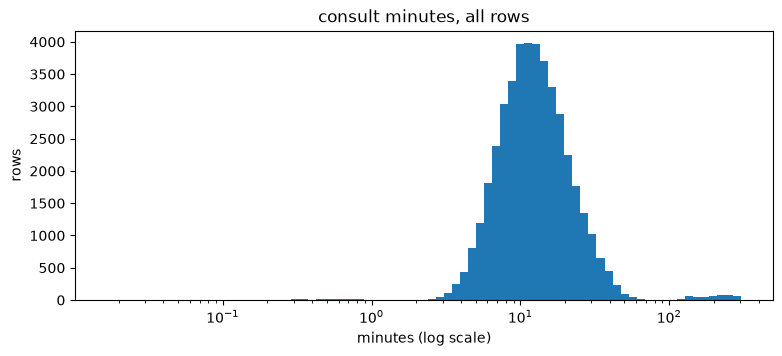

In [84]:
# Given: the shape of the target on a log scale (run after your cell above)
log_hist(minutes, title="consult minutes, all rows")
plt.show()

In [85]:
# TODO(you):
# 1. IQR fences on minutes, then on np.log(minutes). How many rows does each flag? Which do you trust more, and why?
Q1 = minutes.quantile(0.25)
Q3 = minutes.quantile(0.75)
IQR = Q3 - Q1
fence_low = Q1 - 1.5 * IQR
fence_high = Q3 + 1.5 * IQR
flag_minutes = (minutes < fence_low) | (minutes > fence_high)
flag_minutes = (minutes < fence_low) | (minutes > fence_high)
print("Number of Flags by Minutes:", flag_minutes.sum())

# log only defined for positive values; others become NaN (and are not flagged)
log_minutes = np.log(minutes.where(minutes > 0))           
Q1_log = log_minutes.quantile(0.25) # type: ignore
Q3_log = log_minutes.quantile(0.75) # type: ignore
IQR_log = Q3_log - Q1_log
fence_low_log = Q1_log - 1.5 * IQR_log
fence_high_log = Q3_log + 1.5 * IQR_log
flag_log_minutes = (log_minutes < fence_low_log) | (log_minutes > fence_high_log)
print("Number of Flags by Log Minutes:", flag_log_minutes.sum())

# Display the rows flagged by each method for comparison
print("Flagged by Minutes")
display(raw[flag_minutes])
print("Flagged by Log Minutes")
display(raw[flag_log_minutes])

# 3. Compare the flagged rows with the original minutes column
print("Minutes Flagged by Minutes")
display(minutes[flag_minutes])
print("Minutes Flagged by Log Minutes")
display(minutes[flag_log_minutes])

# 2. Print the 10 shortest and 10 longest consults with all their columns. What do they have in common?
shortest_idx = minutes.nsmallest(10).index
longest_idx = minutes.nlargest(10).index
print("Shortest Consults")
display(raw.loc[shortest_idx])
print("Longest Consults")
display(raw.loc[longest_idx])

# 4. Compare the flagged rows with the shortest and longest consults
flagged_minutes_idx = flag_minutes.index[flag_minutes.to_numpy()]
print("Shortest Consults Flagged by Minutes")
display(raw.loc[shortest_idx.intersection(flagged_minutes_idx)])
print("Longest Consults Flagged by Minutes")
display(raw.loc[longest_idx.intersection(flagged_minutes_idx)])

Number of Flags by Minutes: 2204
Number of Flags by Log Minutes: 778
Flagged by Minutes


,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,interpreter,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
76,A038917,2026-08-05,11:30,Jayanagar,Anita Sharma,Cardiology,P00833,Aarav,54.0,False,new,2,False,2026-08-05 11:17:00,2026-08-05 11:31:09,2026-08-05 12:11:07,2026-08-05 11:30:00
81,A013390,2026-03-17,15:00,Whitefield,Neha Gupta,General Medicine,P05711,Vandana,46.0,False,new,3,False,2026-03-17 14:50:07,2026-03-17 14:50:07,2026-03-17 15:28:10,2026-03-17 15:00:00
95,A019526,2026-04-20,10:45,Whitefield,Neha Gupta,General Medicine,P04973,Aadhya,17.0,False,new,2,False,2026-04-20 10:26:14,2026-04-20 10:26:14,2026-04-20 11:05:49,2026-04-20 10:45:00
119,A015248,2026-03-27,16:30,Whitefield,Neha Gupta,General Medicine,P03800,Ramesh,NaN,False,new,3,False,2026-03-27 16:17:13,2026-03-27 16:17:13,2026-03-27 16:51:44,2026-03-27 16:30:00
123,A007095,2026-02-09,14:30,HSR,Farah Siddiqui,Neurology,P04580,Myra,75.0,False,new,3,False,2026-02-09 14:21:17,2026-02-09 14:31:02,2026-02-09 15:06:42,2026-02-09 14:30:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43810,A019173,2026-04-17,11:45,Koramangala,Rohan Desai,ENT,P03862,Yash,49.0,False,new,3,False,2026-04-17 11:40:59,2026-04-17 11:45:41,2026-04-17 13:58:41,2026-04-17 11:45:00
43811,A033375,2026-07-04,10:30,Indiranagar,Sanjay Patil,Paediatrics,P00791,Lakshmi,4.0,True,follow-up,0,False,2026-07-04 10:25:01,2026-07-04 10:32:03,2026-07-04 13:06:03,2026-07-04 10:30:00
43828,A035232,2026-07-15,15:00,Whitefield,Lakshmi Krishnan,Gynaecology,P02468,Om,33.0,False,follow-up,0,False,2026-07-15 14:52:17,2026-07-15 15:02:17,2026-07-15 17:14:36,2026-07-15 15:00:00
43916,A018877,2026-04-16,12:15,Whitefield,Arjun Reddy,Orthopaedics,P02610,Thomas,64.0,False,follow-up,2,False,2026-04-16 12:05:26,2026-04-16 12:05:26,2026-04-16 12:37:31,2026-04-16 12:15:00


Flagged by Log Minutes


,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,interpreter,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
79,A006950,2026-02-07,14:45,Indiranagar,Pooja Bhat,Paediatrics,P05879,Anika,13.0,False,new,2,False,2026-02-07 14:44:20,2026-02-07 14:47:59,2026-02-07 14:48:01,2026-02-07 14:45:00
187,A010769,2026-03-02,17:45,Indiranagar,Imran Khan,General Medicine,P01004,Rahul,33.0,False,follow-up,1,False,2026-03-02 17:29:48,2026-03-02 17:45:05,2026-03-02 21:21:27,2026-03-02 17:45:00
213,A002005,2026-01-12,17:00,Indiranagar,Sanjay Patil,Paediatrics,P02690,Om,5.0,False,new,1,False,2026-01-12 16:58:46,2026-01-12 17:03:27,2026-01-12 21:25:33,2026-01-12 17:00:00
228,A004953,2026-01-28,09:30,Koramangala,Sanjay Patil,Paediatrics,P05750,Rahul,10.0,False,new,2,False,2026-01-28 09:17:11,2026-01-28 09:32:58,2026-01-28 13:39:28,2026-01-28 09:30:00
229,A037687,2026-07-29,11:15,Indiranagar,Sanjay Patil,Paediatrics,P00536,Manoj,6.0,False,review,2,False,2026-07-29 11:11:57,2026-07-29 11:20:34,2026-07-29 16:02:32,2026-07-29 11:15:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43810,A019173,2026-04-17,11:45,Koramangala,Rohan Desai,ENT,P03862,Yash,49.0,False,new,3,False,2026-04-17 11:40:59,2026-04-17 11:45:41,2026-04-17 13:58:41,2026-04-17 11:45:00
43811,A033375,2026-07-04,10:30,Indiranagar,Sanjay Patil,Paediatrics,P00791,Lakshmi,4.0,True,follow-up,0,False,2026-07-04 10:25:01,2026-07-04 10:32:03,2026-07-04 13:06:03,2026-07-04 10:30:00
43828,A035232,2026-07-15,15:00,Whitefield,Lakshmi Krishnan,Gynaecology,P02468,Om,33.0,False,follow-up,0,False,2026-07-15 14:52:17,2026-07-15 15:02:17,2026-07-15 17:14:36,2026-07-15 15:00:00
43870,A004569,2026-01-26,15:00,Jayanagar,Neha Gupta,General Medicine,P02192,Kiara,33.0,True,new,1,False,2026-01-26 14:47:16,2026-01-26 15:00:24,2026-01-26 15:00:41,2026-01-26 15:00:00


Minutes Flagged by Minutes


...

,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,interpreter,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
12211,A020635,2026-04-25,12:30,Whitefield,Farah Siddiqui,Neurology,P00687,Vandana,22.0,False,review,2,False,2026-04-25 12:19:11,2026-04-25 12:19:11,2026-04-25 17:22:40,2026-04-25 12:30:00
4229,A015274,2026-03-27,16:00,Whitefield,DR LAKSHMI KRISHNAN,Gynaecology,P00441,Zoya,59.0,False,new,2,False,2026-03-27 15:59:44,2026-03-27 15:59:44,2026-03-27 20:59:41,2026-03-27 16:00:00
8231,A041578,2026-08-19,11:15,Whitefield,Rahul Menon,Cardiology,P00830,Uma,45.0,True,New,3,False,2026-08-19 10:59:06,2026-08-19 11:16:24,2026-08-19 16:16:17,2026-08-19 11:15:00
6237,A041934,2026-08-21,09:30,Koramangala,Suresh Kumar,Orthopaedics,P05102,Joseph,NaN,False,new,2,False,2026-08-21 09:15:52,2026-08-21 09:41:13,2026-08-21 14:41:05,2026-08-21 09:30:00
37716,A001756,2026-01-10,09:30,Koramangala,Suresh Kumar,Orthopaedics,P04395,Farhan,27.0,False,new,2,False,2026-01-10 09:21:43,2026-01-10 09:33:05,2026-01-10 14:32:53,2026-01-10 09:30:00
20857,A007995,2026-02-13,13:30,Koramangala,Rohan Desai,ENT,P03408,Aditya,55.0,False,new,1,False,2026-02-13 13:10:54,2026-02-13 13:39:23,2026-02-13 18:38:06,2026-02-13 13:30:00
13964,A040107,2026-08-11,12:00,Jayanagar,Anita Sharma,Cardiology,P00591,Kiran,59.0,False,new,3,False,2026-08-11 11:45:50,2026-08-11 12:01:03,2026-08-11 16:59:39,2026-08-11 12:00:00
42319,A005687,2026-01-31,15:15,Indiranagar,Karthik Subramanian,Cardiology,P02625,Ira,29.0,False,new,5,False,2026-01-31 15:09:29,2026-01-31 15:20:21,2026-01-31 20:17:35,2026-01-31 15:15:00
42170,A033148,2026-07-03,11:15,Whitefield,Lakshmi Krishnan,Gynaecology,P02274,Imran,29.0,False,follow-up,2,False,2026-07-03 11:07:01,2026-07-03 11:19:06,2026-07-03 16:16:06,2026-07-03 11:15:00
21491,A038388,2026-08-01,15:15,Indiranagar,Imran Khan,General Medicine,P04271,Sunita,48.0,False,follow-up,0,False,2026-08-01 15:12:55,2026-08-01 15:20:59,2026-08-01 20:16:55,2026-08-01 15:15:00


Shortest Consults Flagged by Minutes


,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,interpreter,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt


Longest Consults Flagged by Minutes


,appointment_id,date,slot_time,clinic,doctor,department,patient_id,patient_name,age,interpreter,visit_type,prior_reports,teleconsult,check_in,consult_start,consult_end,slot_dt
12211,A020635,2026-04-25,12:30,Whitefield,Farah Siddiqui,Neurology,P00687,Vandana,22.0,False,review,2,False,2026-04-25 12:19:11,2026-04-25 12:19:11,2026-04-25 17:22:40,2026-04-25 12:30:00
4229,A015274,2026-03-27,16:00,Whitefield,DR LAKSHMI KRISHNAN,Gynaecology,P00441,Zoya,59.0,False,new,2,False,2026-03-27 15:59:44,2026-03-27 15:59:44,2026-03-27 20:59:41,2026-03-27 16:00:00
8231,A041578,2026-08-19,11:15,Whitefield,Rahul Menon,Cardiology,P00830,Uma,45.0,True,New,3,False,2026-08-19 10:59:06,2026-08-19 11:16:24,2026-08-19 16:16:17,2026-08-19 11:15:00
6237,A041934,2026-08-21,09:30,Koramangala,Suresh Kumar,Orthopaedics,P05102,Joseph,NaN,False,new,2,False,2026-08-21 09:15:52,2026-08-21 09:41:13,2026-08-21 14:41:05,2026-08-21 09:30:00
37716,A001756,2026-01-10,09:30,Koramangala,Suresh Kumar,Orthopaedics,P04395,Farhan,27.0,False,new,2,False,2026-01-10 09:21:43,2026-01-10 09:33:05,2026-01-10 14:32:53,2026-01-10 09:30:00
20857,A007995,2026-02-13,13:30,Koramangala,Rohan Desai,ENT,P03408,Aditya,55.0,False,new,1,False,2026-02-13 13:10:54,2026-02-13 13:39:23,2026-02-13 18:38:06,2026-02-13 13:30:00
13964,A040107,2026-08-11,12:00,Jayanagar,Anita Sharma,Cardiology,P00591,Kiran,59.0,False,new,3,False,2026-08-11 11:45:50,2026-08-11 12:01:03,2026-08-11 16:59:39,2026-08-11 12:00:00
42319,A005687,2026-01-31,15:15,Indiranagar,Karthik Subramanian,Cardiology,P02625,Ira,29.0,False,new,5,False,2026-01-31 15:09:29,2026-01-31 15:20:21,2026-01-31 20:17:35,2026-01-31 15:15:00
42170,A033148,2026-07-03,11:15,Whitefield,Lakshmi Krishnan,Gynaecology,P02274,Imran,29.0,False,follow-up,2,False,2026-07-03 11:07:01,2026-07-03 11:19:06,2026-07-03 16:16:06,2026-07-03 11:15:00
21491,A038388,2026-08-01,15:15,Indiranagar,Imran Khan,General Medicine,P04271,Sunita,48.0,False,follow-up,0,False,2026-08-01 15:12:55,2026-08-01 15:20:59,2026-08-01 20:16:55,2026-08-01 15:15:00


**Which outlier method do I trust?**

*Answer:* the **log-scale IQR** is better than the raw-scale IQR, but neither is the right tool for finding *impossible* rows; the **domain rule** is.

- **Raw IQR (2,204 rows):** consult times are right-skewed, so the upper fence sits low (~30 min). It flags many *genuine* long consults (32-40 min) and throws away real, rare data. It also flags **no** very short consults, so it misses the impossible 2-second ones.
- **Log IQR (778 rows):** removes the skew, so it catches both tails (e.g. 0.03 min and 216-282 min) and only flags what is unusual on a multiplicative scale. Much less collateral damage.
- **Domain rule (<1 min or >120 min, 669 rows):** targets exactly what is *impossible*. Statistics say what is *unusual*; only domain knowledge says what is *wrong*.

**Decision:** use the domain rule to remove impossible rows, and the log-IQR only as a secondary "look at these" flag. Long-but-plausible visits (e.g. 40-120 min) must stay, otherwise the model learns that long consults never happen.

## Check 7 - Consistency over time, places and timestamps

**Why:** a process change (new software, new reception staff, a new rule) shows up as a **step** in a time plot. A model trained across the step learns a mixture of two different processes.

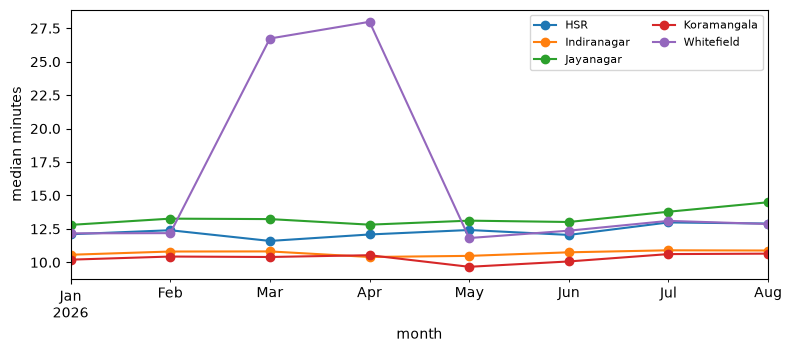

clinic,HSR,Indiranagar,Jayanagar,Koramangala,Whitefield
month,,,,,
2026-01-01,12.1,10.6,12.8,10.2,12.2
2026-02-01,12.4,10.8,13.3,10.4,12.2
2026-03-01,11.6,10.8,13.2,10.4,26.7
2026-04-01,12.1,10.4,12.8,10.5,28.0
2026-05-01,12.4,10.5,13.1,9.7,11.8
2026-06-01,12.0,10.8,13.0,10.1,12.4
2026-07-01,13.0,10.9,13.8,10.6,13.1
2026-08-01,12.9,10.9,14.5,10.6,12.9


In [86]:
# Given: monthly median consult minutes for each clinic (needs `minutes` from Check 6)
table = monthly_median(raw.assign(minutes=minutes), "minutes", by="clinic")
plt.show()
table.round(1)

In [87]:
# TODO(you): the timestamps should follow   check_in  <=  consult_start  <  consult_end
# 1. How many rows break each part of that order? How many have consult_start EXACTLY equal to check_in?
violations = pd.Series({
    "consult_start < check_in":        (raw["consult_start"] < raw["check_in"]).sum(),
    "consult_end <= consult_start":    (raw["consult_end"] <= raw["consult_start"]).sum(),
    "consult_start == check_in":       (raw["consult_start"] == raw["check_in"]).sum(),
    "consult_end == consult_start":    (raw["consult_end"] == raw["consult_start"]).sum(),
})
display(violations)

# 2. Where and when do those rows happen?     hint: groupby clinic and month

flags = raw.assign(
    month=raw["date"].dt.to_period("M"),
    start_before_checkin=raw["consult_start"] < raw["check_in"],
    end_not_after_start=raw["consult_end"] <= raw["consult_start"],
    start_eq_checkin=raw["consult_start"] == raw["check_in"],
)

cols = ["start_before_checkin", "end_not_after_start", "start_eq_checkin"]
display(flags.groupby("clinic")[cols].sum())
display(flags.groupby("month")[cols].sum())
display(flags.groupby(["clinic", "month"])[cols].sum().unstack("clinic"))

consult_start < check_in           0
consult_end <= consult_start       4
consult_start == check_in       1753
consult_end == consult_start       4
dtype: int64

,start_before_checkin,end_not_after_start,start_eq_checkin
clinic,,,
HSR,0,0,0
Indiranagar,0,2,0
Jayanagar,0,0,0
Koramangala,0,1,0
Whitefield,0,1,1753


,start_before_checkin,end_not_after_start,start_eq_checkin
month,,,
2026-01,0,0,0
2026-02,0,0,0
2026-03,0,0,936
2026-04,0,0,817
2026-05,0,1,0
2026-06,0,0,0
2026-07,0,2,0
2026-08,0,1,0


start_before_checkin                                               \
clinic                   HSR Indiranagar Jayanagar Koramangala Whitefield   
month                                                                       
2026-01                    0           0         0           0          0   
2026-02                    0           0         0           0          0   
2026-03                    0           0         0           0          0   
2026-04                    0           0         0           0          0   
2026-05                    0           0         0           0          0   
2026-06                    0           0         0           0          0   
2026-07                    0           0         0           0          0   
2026-08                    0           0         0           0          0   

        end_not_after_start                                               \
clinic                  HSR Indiranagar Jayanagar Koramangala Whitefield   
month                                                                      
2026-01                   0           0         0           0          0   
2026-02                   0           0         0           0          0   
2026-03                   0           0         0           0          0   
2026-04                   0           0         0           0          0   
2026-05                   0           0         0           1          0   
2026-06                   0           0         0           0          0   
2026-07                   0           1         0           0          1   
2026-08                   0           1         0           0          0   

        start_eq_checkin                                               
clinic               HSR Indiranagar Jayanagar Koramangala Whitefield  
month                                                                  
2026-01                0           0         0           0          0  
2026-02                0           0         0           0          0  
2026-03                0           0         0           0        936  
2026-04                0           0         0           0        817  
2026-05                0           0         0           0          0  
2026-06                0           0         0           0          0  
2026-07                0           0         0           0          0  
2026-08                0           0         0           0          0

## Check 8 - Leakage smells

**Why:** a feature is only allowed if it is **known when the slot is booked**, days before the visit. Fill in the table: for each column, is it known at booking? Is it the target or used to build it? Is it useless or risky?

| Column | Known at booking? | Use as a feature? | Why |
|---|---|---|---|
| appointment_id |yes |no |unique->identify the appointment but dont give info about the visit it self |
| date, slot_time |yes |yes |help with predict on taht day for time |
| clinic, doctor, department |yes | yes| need slot per deprt/doctor/clilic |
| patient_id, patient_name |yes |no |can be different while prediction for new appointment type this may not be known |
| age, interpreter, prior_reports |yes |yes |this will be the signal for training the hidden rules the model need to precit |
| visit_type, teleconsult | yes| yes|need for solt |
| check_in |no |no |only known once patient arrived |
| consult_start, consult_end |no | no|only known once appointment stared |

Hint for `appointment_id`: are the ids random, or do they encode something else?

## Wrap-up

1. **How many of the 8 problem kinds did you log?** All 8 (duplicates, inconsistent labels, age 999, missing age, missing `consult_end`, impossible durations, Whitefield process change, broken timestamp order).

2. **MCAR / MAR / MNAR, and does dropping bias the data?**

| # | Problem | Type | Drop rows? |
|---|---|---|---|
| 1 | Duplicates | Not a missingness problem (copies) | Safe: drop the extra copy, keep one |
| 2 | Inconsistent labels | Not missing | Don't drop, normalise/map instead |
| 3 | Age 999 | Hidden missing, MCAR-like (spread evenly) | Better to set NaN and impute than drop |
| 4 | Missing age | MCAR-like (flat 1.9-2.1% across clinics) | Dropping is low risk, but imputing keeps rows |
| 5 | Missing `consult_end` | MCAR-like (flat across clinics and months); watch for MNAR if the very long visits are the ones left unclosed | Low risk to drop (0.23%), but check the missing rows are not mostly long visits |
| 6 | Impossible durations | Errors; possibly partly MNAR-like (the "forgot to close" long visits) | Drop the impossible ones, but only after confirming it does not remove a whole kind of visit |
| 7 | Whitefield Mar-Apr (`start == check_in`) | **MAR**: depends on clinic and period, which we can see | **Yes, biased**: dropping removes about 23% of Whitefield's rows (1,753 of 7,581) and two whole months |
| 8 | Order broken (4 rows) | Random errors | Safe to drop (tiny) |

   **Whitefield, better fix than dropping:** `consult_start` is broken but `consult_end` is fine, and the other features (doctor, department, visit type, age, slot) are fine too. So keep the rows and treat only the *target/start* as bad: set `consult_start` to missing for those 1,753 rows and either (a) exclude them from computing the target while still using them for other analysis, or (b) re-estimate the true start (e.g. `consult_end` minus the typical duration for that doctor/visit type, from Whitefield's good months), or (c) add a "Whitefield Mar-Apr" flag so the model can separate the two processes. Note that for these rows `consult_end - check_in` is **wait + consult**, not consult time, so it must not be used as the target directly.

3. **Which problem hurts the model most if missed?** **The Whitefield change (#7).** It silently doubles the target (median ~27 vs ~12 min) for one clinic over two months, so the model would learn a false "Whitefield is slow" pattern. The other problems are small (<2% each) or easy to spot, while this one is large, systematic and looks like valid data.